## Graph 2: Minutes using AI Relative to Time Spent Procrasinating

**Graph Type:** Parallel Coordinate Plot

**Description:** This parallel coordinate plot compares minutes of AI used with time spent procrastinating with each line representing one student and each axis representing a different type of procrastination: sleeping/napping, hanging out with friends, completing easier or other assignments, watching shows/movies, social media (Instagram, TikTok, etc.), and gaming. Lines that rise or fall together across the axes show which kinds of procrastination tend to go along with heavier or lighter AI use. Where lines cluster tightly, a pattern is shared across students. Where they spread out or cross, the relationship is weaker or varies by person.

**Hypothesis:** Students who use AI for more minutes spend less time procrastinating overall, and certain types of procrastination, such as completing easier assignments, are less likely to use as much AI as others, such as gaming or social media.

**Conclusion:** There is no clear relationship between how many minutes students used AI and how they procrastinate. AI usage does not appear to depend on how a student procrastinates, but social media is the dominant procrastination activity across all AI usage levels

**Status:** In Progress

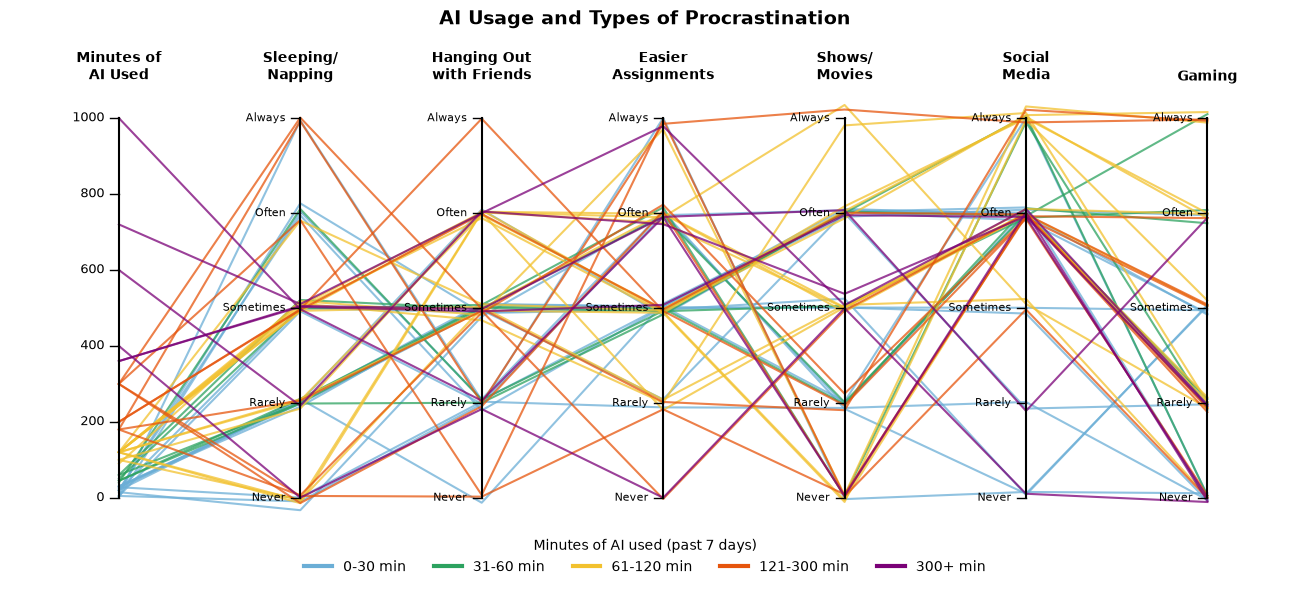

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("survey.csv")

# Procrastination columns (Sleeping/Napping ... Gaming)
proc_df = survey_df.loc[:, "If you procrastinate, what do you typically spend your time doing?  [Sleeping/Napping]":
                           "If you procrastinate, what do you typically spend your time doing?  [Gaming]"].copy()
proc_df.columns = ["Sleeping/\nNapping", "Hanging Out\nwith Friends", "Easier\nAssignments",
                   "Shows/\nMovies", "Social\nMedia", "Gaming"]

# Add the minutes of AI used in the past 7 days
minutes_col = [c for c in survey_df.columns if c.startswith("In the past 7 days, approximately how many minutes")][0]
ai_col = "Minutes of\nAI Used"
proc_df[ai_col] = pd.to_numeric(survey_df[minutes_col], errors="coerce")

# Convert the answers into numbers: Never = 1 ... Always = 5
scale = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5}
procrastination_types = [c for c in proc_df.columns if c != ai_col]
for col in procrastination_types:
    proc_df[col] = proc_df[col].map(scale)   # a few people checked 2 boxes -> become blank and are dropped below

# Remove rows with blank values
proc_df = proc_df.dropna()

# Sort so students with the most AI minutes are drawn last (on top of the others)
proc_df = proc_df.sort_values(ai_col)

# Put every axis on a 0-1 scale so they can share one plot (each axis keeps its own tick labels)
ai_max = 1000
scaled_df = pd.DataFrame({ai_col: proc_df[ai_col] / ai_max})
for col in procrastination_types:
    scaled_df[col] = (proc_df[col] - 1) / 4

columns = [ai_col] + procrastination_types
x = np.arange(len(columns))

# Group AI minutes into bins, each with its own clearly different color
bins = [-1, 30, 60, 120, 300, 2000]
bin_labels = ["0-30 min", "31-60 min", "61-120 min", "121-300 min", "300+ min"]
bin_colors = ["#6baed6", "#2ca25f", "#f2c12e", "#e6550d", "#7a0177"]   # light blue, green, yellow, orange, purple
group = pd.cut(proc_df[ai_col], bins=bins, labels=bin_labels)
color_map = dict(zip(bin_labels, bin_colors))

# Create the parallel coordinate plot
fig, ax = plt.subplots(figsize=(13, 6))
rng = np.random.default_rng(1)
for idx in scaled_df.index:
    y = scaled_df.loc[idx, columns].values.astype(float)
    y[1:] += rng.normal(0, 0.012, len(columns) - 1)
    ax.plot(x, y, color=color_map[group[idx]], alpha=0.75, linewidth=1.5)

# Draw each vertical axis with its own title
for xi, col in zip(x, columns):
    ax.plot([xi, xi], [0, 1], color="black", linewidth=1.5)
    ax.text(xi, 1.09, col, ha="center", va="bottom", fontsize=10, fontweight="bold")

for m in range(0, 1001, 200):
    pos = m / ai_max
    ax.plot([-0.05, 0], [pos, pos], color="black", linewidth=1)
    ax.text(-0.08, pos, str(m), ha="right", va="center", fontsize=9)

for xi in x[1:]:
    for score, label in enumerate(["Never", "Rarely", "Sometimes", "Often", "Always"]):
        ax.plot([xi - 0.05, xi], [score / 4, score / 4], color="black", linewidth=1)
        ax.text(xi - 0.08, score / 4, label, ha="right", va="center", fontsize=8)

ax.set_xlim(-0.6, len(columns) - 0.6)
ax.set_ylim(-0.05, 1.2)
ax.axis("off")
plt.title("AI Usage and Types of Procrastination", fontsize=14, fontweight="bold", y=1.02)

ax.legend(handles=[Line2D([0], [0], color=c, lw=3, label=l) for l, c in color_map.items()],
          title="Minutes of AI used (past 7 days)", loc="upper center",
          bbox_to_anchor=(0.5, -0.02), ncol=5, frameon=False)
plt.tight_layout()
plt.show()